<a href="https://colab.research.google.com/github/moy850/avionica-reto-2026/blob/main/generate_flight.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
print("sistema de telemetria de AAIAQ")


sistema de telemetria de AAIAQ


In [ ]:
# SIMULADOR DE VUELO AAIAQ

# Parámetros generales
dt = 0.1                 # Intervalo de tiempo: 100 ms
frecuencia = 10          # 10 muestras por segundo
gravedad = 9.81          # Gravedad en m/s²

# Duración de las etapas
tiempo_rampa = 2.0
tiempo_propulsion = 1.5
tiempo_tierra = 3.0

# Parámetros del vuelo
aceleracion = 60.0       # Aceleración neta hacia arriba
velocidad_paracaidas = 6.0  # Descenso en m/s

print("Parámetros del vuelo configurados")

Parámetros del vuelo configurados


In [ ]:
# Crear las carpetas del proyecto

import os

os.makedirs("src", exist_ok=True)
os.makedirs("docs", exist_ok=True)
os.makedirs("media", exist_ok=True)

print("Carpetas del proyecto creadas:")
print("src - Programas")
print("docs - Documentación")
print("media - Gráficas e imágenes")

Carpetas del proyecto creadas:
src - Programas
docs - Documentación
media - Gráficas e imágenes


In [ ]:
# PRIMERA SIMULACIÓN: PROPULSIÓN

dt = 0.1          # Intervalo de tiempo: 100 ms
aceleracion = 60  # Aceleración del cohete

velocidad = 0
altitud = 0
tiempo = 0

while tiempo < 1.5:

    altitud = altitud + velocidad * dt + 0.5 * aceleracion * dt**2

    velocidad = velocidad + aceleracion * dt

    tiempo = tiempo + dt

print("Tiempo:", tiempo, "segundos")
print("Altitud:", round(altitud, 2), "metros")
print("Velocidad:", round(velocidad, 2), "m/s")

Tiempo: 1.5000000000000002 segundos
Altitud: 67.5 metros
Velocidad: 90.0 m/s


In [ ]:
# FASE 2: VUELO BALÍSTICO

dt = 0.1
gravedad = -9.81

# Condiciones al terminar la propulsión
altitud = 67.5
velocidad = 90
tiempo = 1.5

# Guardar los datos
tiempos = [tiempo]
altitudes = [altitud]
velocidades = [velocidad]

# Simular mientras el cohete siga subiendo
while velocidad > 0:

    altitud = altitud + velocidad * dt + 0.5 * gravedad * dt**2

    velocidad = velocidad + gravedad * dt

    tiempo = tiempo + dt

    tiempos.append(tiempo)
    altitudes.append(altitud)
    velocidades.append(velocidad)

print("APOGEO DEL COHETE")
print("Altitud máxima:", round(max(altitudes), 2), "metros")
print("Tiempo:", round(tiempo, 2), "segundos")
print("Velocidad final:", round(velocidad, 2), "m/s")

APOGEO DEL COHETE
Altitud máxima: 480.34 metros
Tiempo: 10.7 segundos
Velocidad final: -0.25 m/s


In [ ]:
# FASE 3: DESCENSO CON PARACAIDAS

# Recuperar el apogeo de la simulacion anterior
altitud = max(altitudes)
indice_apogeo = altitudes.index(altitud)
tiempo = tiempos[indice_apogeo]

# Velocidad de descenso
velocidad = -6

# Guardar los datos del descenso
descenso_tiempos = [tiempo]
descenso_altitudes = [altitud]

dt = 0.1

while altitud > 0:

    altitud = altitud + velocidad * dt

    tiempo = tiempo + dt

    # Evitar altitudes negativas
    if altitud < 0:
        altitud = 0

    descenso_tiempos.append(tiempo)
    descenso_altitudes.append(altitud)

print("DESCENSO CON PARACAIDAS")
print("Altitud final:", altitud, "metros")
print("Tiempo de descenso:", round(tiempo - tiempos[indice_apogeo], 2), "segundos")

DESCENSO CON PARACAIDAS
Altitud final: 0 metros
Tiempo de descenso: 80.1 segundos


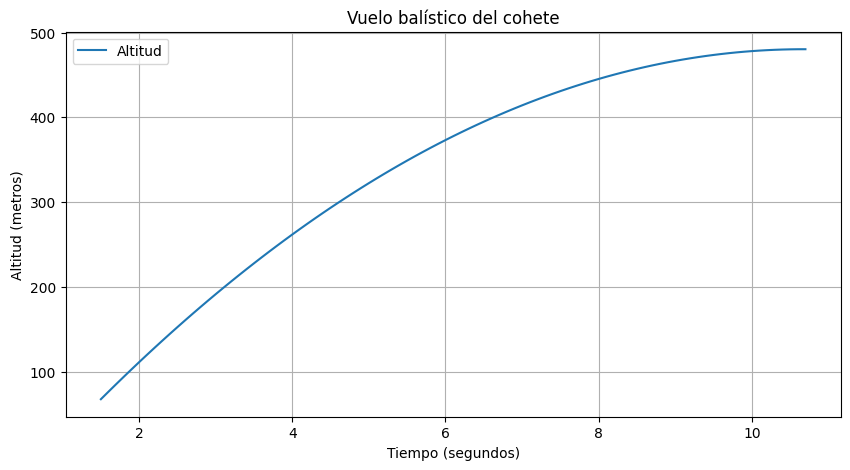

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(tiempos, altitudes, label="Altitud")

plt.xlabel("Tiempo (segundos)")
plt.ylabel("Altitud (metros)")
plt.title("Vuelo balístico del cohete")

plt.grid()
plt.legend()
plt.show()

In [ ]:
# FASE 4: ATERRIZAJE

tiempo_aterrizaje = tiempo

for i in range(1, 31):

    tiempo = tiempo_aterrizaje + i * 0.1

    descenso_tiempos.append(tiempo)
    descenso_altitudes.append(0)

print("ATERRIZAJE COMPLETADO")
print("Tiempo final:", round(tiempo, 2), "segundos")
print("Altitud final: 0 metros")

In [ ]:
!git push --all origin

fatal: not a git repository (or any of the parent directories): .git


In [ ]:
s